# 02 — Exploratory Data Analysis of the Cleaned Loan Default Dataset

## 1. Reproducible setup and cleaned-data gate

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.ticker import EngFormatter
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'data').exists():
    raise FileNotFoundError('Open this notebook from the Machine_Learning project folder or notebooks folder.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.eda_preprocessing import (
    categorical_association_with_target,
    categorical_summary,
    column_profile,
    configure_plots,
    dataset_overview,
    feature_dictionary,
    iqr_outlier_summary,
    missingness_target_audit,
    numeric_summary,
    save_figure,
    save_table,
)

CLEANED_DATA = PROJECT_ROOT / 'data' / 'processed' / 'loan_default_cleaned.csv'
CLEANING_TABLES = PROJECT_ROOT / 'outputs' / 'tables' / 'cleaning'
EDA_TABLES = PROJECT_ROOT / 'outputs' / 'tables' / 'eda'
EDA_FIGURES = PROJECT_ROOT / 'outputs' / 'figures' / 'eda'
EDA_TABLES.mkdir(parents=True, exist_ok=True)
EDA_FIGURES.mkdir(parents=True, exist_ok=True)

if not CLEANED_DATA.exists():
    raise FileNotFoundError('Cleaned dataset is missing. Run 01_data_cleaning.ipynb first.')

df = pd.read_csv(CLEANED_DATA)
required = {'id', 'status', 'loan_amount', 'credit_score'}
assert required.issubset(df.columns), 'Cleaned-data schema check failed.'
assert df['status'].notna().all() and set(df['status'].unique()) == {0, 1}
assert df['id'].is_unique, 'Cleaned-data gate failed: duplicate IDs detected.'
assert not df.duplicated().any(), 'Cleaned-data gate failed: exact duplicates detected.'

configure_plots()
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_colwidth', 100)
print(f'Loaded cleaned data only: {CLEANED_DATA}')
print(f'Shape: {df.shape[0]:,} rows × {df.shape[1]} columns')


Loaded cleaned data only: /Users/zichen/Machine_Learning/data/processed/loan_default_cleaned.csv
Shape: 148,670 rows × 34 columns


## 2. Dataset characteristics and feature descriptions


In [2]:
overview = dataset_overview(df)
dictionary = feature_dictionary(df)
save_table(overview, EDA_TABLES / 'dataset_overview.csv')
save_table(dictionary, EDA_TABLES / 'feature_dictionary.csv')
display(overview)
display(dictionary)


,metric,value
0,observations,148670.000
1,attributes,34.000
2,numeric_attributes,13.000
3,categorical_attributes,21.000
4,exact_duplicates,0.000
5,unique_ids,148670.000
6,default_cases,36639.000
7,non_default_cases,112031.000
8,default_rate_pct,24.645


,feature,description,dtype,analytical_role
0,id,Unique loan application identifier; excluded from modelling.,int64,identifier
1,year,Calendar year of the application record.,int64,constant / exclude
2,loan_limit,Whether the loan conforms to the applicable loan limit.,object,candidate predictor
3,gender,Applicant gender category as supplied by the source dataset.,object,candidate predictor
4,approv_in_adv,Whether approval was obtained in advance.,object,candidate predictor
5,loan_type,Source-coded loan product type.,object,candidate predictor
6,loan_purpose,Source-coded purpose of the loan.,object,candidate predictor
7,credit_worthiness,Source-coded credit-worthiness category.,object,candidate predictor
8,open_credit,Whether the application is an open-credit transaction.,object,candidate predictor
9,business_or_commercial,Whether the loan is business/commercial rather than personal.,object,candidate predictor


## 3. Descriptive statistics, completeness, and skewness


In [3]:
profile = column_profile(df)
num_summary = numeric_summary(df)
save_table(profile, EDA_TABLES / 'column_profile.csv')
save_table(num_summary.reset_index(names='feature'), EDA_TABLES / 'numeric_summary.csv')
display(profile)
display(num_summary)


,feature,dtype,missing_count,missing_pct,unique_including_missing,skewness
13,upfront_charges,float64,39642,26.664,58272,1.754
12,interest_rate_spread,float64,36639,24.645,22517,0.281
11,rate_of_interest,float64,36439,24.510,132,0.388
33,dtir1,float64,24121,16.225,58,-0.551
29,ltv,float64,15098,10.155,8485,120.615
18,property_value,float64,15098,10.155,386,4.586
23,income,float64,9150,6.155,1002,17.308
2,loan_limit,object,3344,2.249,3,NaN
4,approv_in_adv,object,908,0.611,3,NaN
27,age,object,200,0.135,8,NaN


,count,mean,std,min,1%,25%,50%,75%,99%,max,missing_pct,skewness
loan_amount,148670.0,331117.744,183909.310,16500.000,66500.000,196500.000,296500.000,436500.000,856500.00,3.576500e+06,0.000,1.667
rate_of_interest,112231.0,4.045,0.561,0.000,2.875,3.625,3.990,4.375,5.50,8.000000e+00,24.510,0.388
interest_rate_spread,112031.0,0.442,0.513,-3.638,-0.681,0.076,0.390,0.775,1.62,3.357000e+00,24.645,0.281
upfront_charges,109028.0,3224.996,3251.122,0.000,0.000,581.490,2596.450,4812.500,14297.05,6.000000e+04,26.664,1.754
term,148629.0,335.137,58.409,96.000,180.000,360.000,360.000,360.000,360.00,3.600000e+02,0.028,-2.175
property_value,133572.0,497893.466,359935.316,8000.000,88000.000,268000.000,418000.000,628000.000,1808000.00,1.650800e+07,10.155,4.586
income,139520.0,6957.339,6496.586,0.000,600.000,3720.000,5760.000,8520.000,26640.00,5.785800e+05,6.155,17.308
credit_score,148670.0,699.789,115.876,500.000,504.000,599.000,699.000,800.000,897.00,9.000000e+02,0.000,0.005
ltv,133572.0,72.746,39.968,0.967,19.610,60.475,75.136,86.184,102.76,7.831250e+03,10.155,120.615
dtir1,124549.0,37.733,10.545,5.000,8.000,31.000,39.000,45.000,60.00,6.100000e+01,16.225,-0.551


## 4. Feature distributions



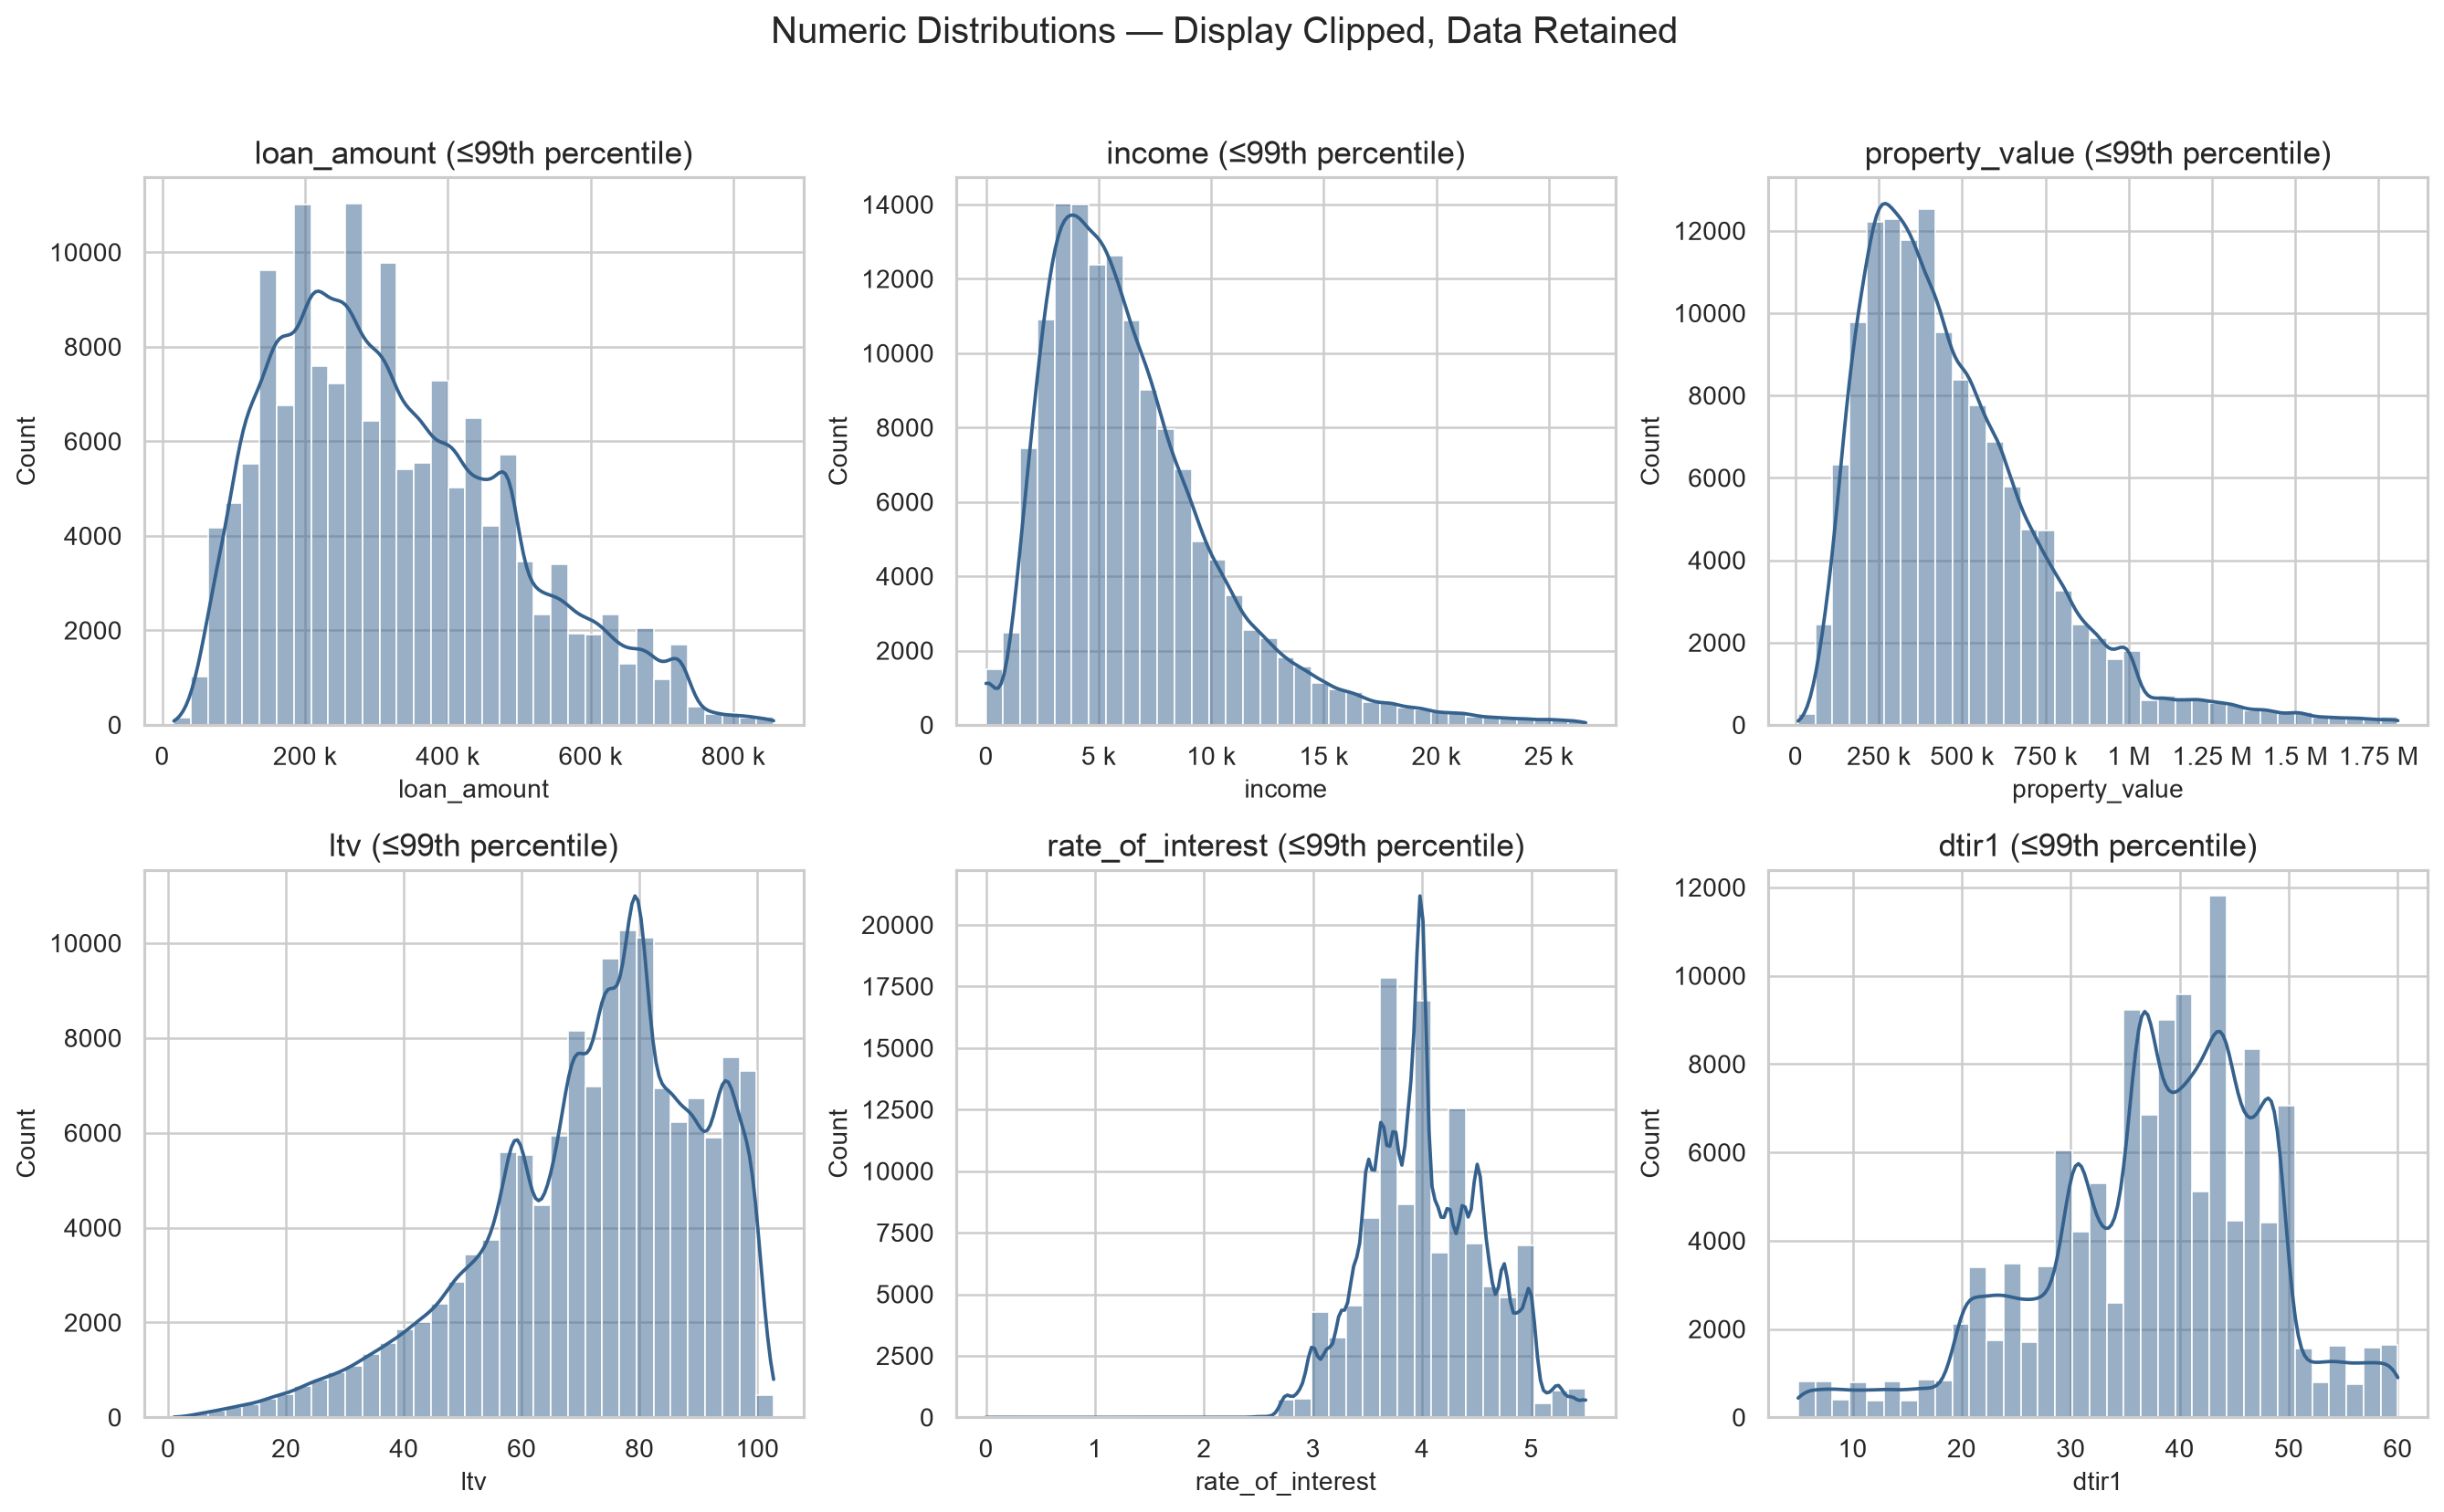

In [4]:
plot_columns = ['loan_amount', 'income', 'property_value', 'ltv', 'rate_of_interest', 'dtir1']
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for column, ax in zip(plot_columns, axes.flat):
    upper = df[column].quantile(0.99)
    sns.histplot(df.loc[df[column].le(upper), column], bins=35, kde=True, ax=ax, color='#35618D')
    ax.set_title(f'{column} (≤99th percentile)')
    ax.xaxis.set_major_formatter(EngFormatter())
fig.suptitle('Numeric Distributions — Display Clipped, Data Retained', y=1.02, fontsize=16)
path = save_figure(EDA_FIGURES / 'numeric_distributions.png')
display(Image(filename=str(path)))


## 5. Missing-value analysis


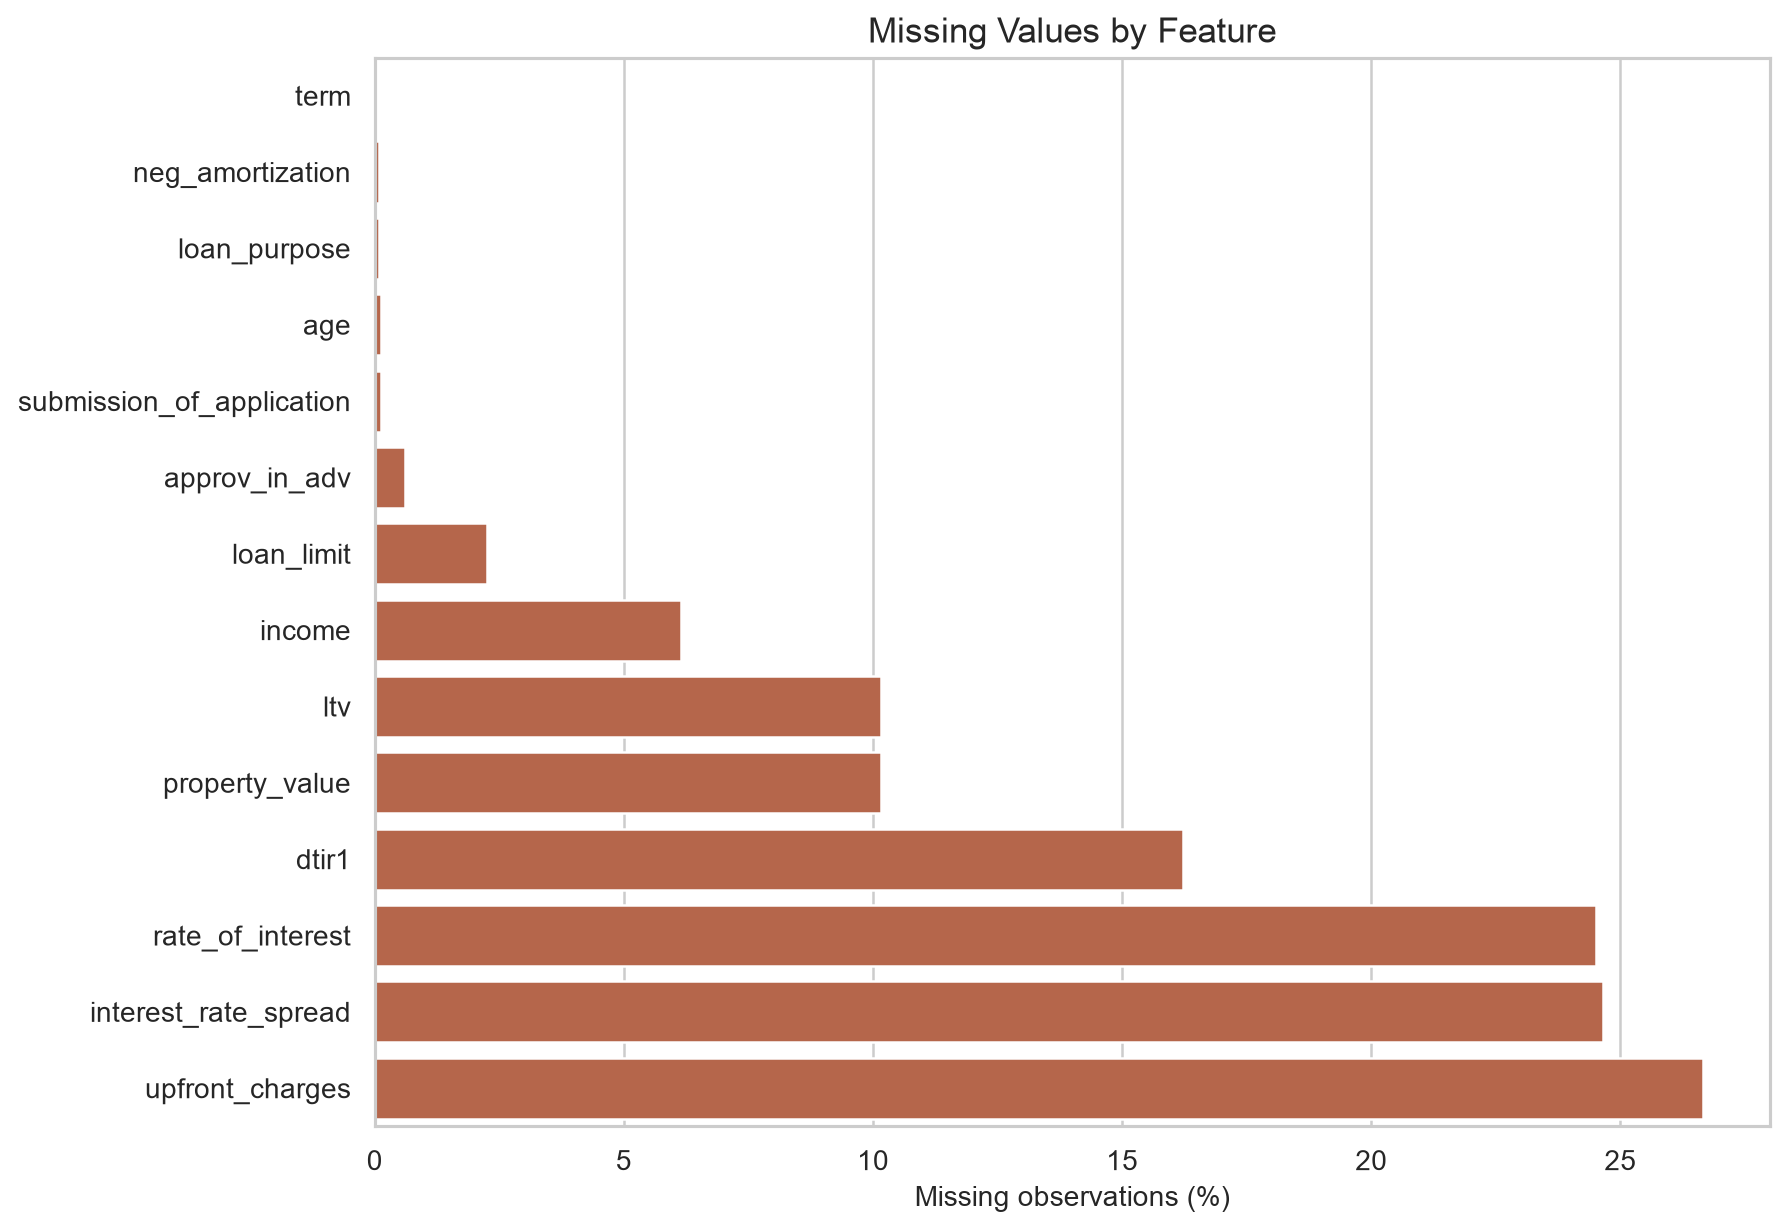

,feature,missing_count,missing_pct,default_rate_when_present_pct,default_rate_when_missing_pct,absolute_rate_gap_pp,perfect_separation_warning
4,interest_rate_spread,36639,24.645,0.000,100.000,100.000,True
3,rate_of_interest,36439,24.510,0.178,100.000,99.822,True
5,upfront_charges,39642,26.664,0.140,92.039,91.898,False
8,property_value,15098,10.155,16.128,99.987,83.858,False
12,ltv,15098,10.155,16.128,99.987,83.858,False
10,age,200,0.135,24.543,100.000,75.457,True
11,submission_of_application,200,0.135,24.543,100.000,75.457,True
13,dtir1,24121,16.225,16.322,67.617,51.295,False
6,term,41,0.028,24.641,36.585,11.944,False
9,income,9150,6.155,25.373,13.541,11.832,False


In [5]:
missing = profile.loc[profile['missing_count'].gt(0)].sort_values('missing_pct')
fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(data=missing, x='missing_pct', y='feature', color='#C65D3A', ax=ax)
ax.set_title('Missing Values by Feature')
ax.set_xlabel('Missing observations (%)')
ax.set_ylabel('')
path = save_figure(EDA_FIGURES / 'missing_values.png')
display(Image(filename=str(path)))

leakage_audit = missingness_target_audit(df)
save_table(leakage_audit, EDA_TABLES / 'missingness_target_audit.csv')
display(leakage_audit)


## 6. Duplicate, noise, inconsistency, and rare-category evidence


In [6]:
cleaning_changes = pd.read_csv(CLEANING_TABLES / 'cleaning_change_log.csv')
validity_findings = pd.read_csv(CLEANING_TABLES / 'validity_audit.csv').query('flagged_count > 0')
post_clean_validation = pd.read_csv(CLEANING_TABLES / 'post_clean_validation.csv')
assert post_clean_validation['passed'].all(), 'Cleaning handoff failed validation.'

print(f"Cleaning validation: {int(post_clean_validation['passed'].sum())}/{len(post_clean_validation)} checks passed")
display(cleaning_changes)
display(validity_findings)

cat_summary = categorical_summary(df)
rare_or_extreme = cat_summary.query('count < 500 or default_rate_pct > 90 or default_rate_pct < 1')
save_table(cat_summary, EDA_TABLES / 'categorical_summary.csv')
save_table(rare_or_extreme, EDA_TABLES / 'rare_or_extreme_categories.csv')
display(rare_or_extreme.sort_values(['default_rate_pct', 'count'], ascending=[False, True]))

Cleaning validation: 11/11 checks passed


,cleaning_action,items_changed,reason,risk_or_limitation
0,Standardise column names to snake_case and correct neg_amortization spelling,13,"Consistent, reproducible feature naming","Names change, but values do not"
1,Strip leading/trailing whitespace from categorical values,0,Prevent accidental duplicate categories,Internal whitespace is intentionally preserved
2,Standardise south/central region capitalisation,72713,Merge labels that differ only by case,Assumes case has no semantic meaning
3,Correct Indriect security label to Indirect,33,Treat apparent spelling error as one category,Assumption should be confirmed against source documentation
4,Remove exact duplicate rows,0,Prevent repeated identical observations,No deduplication is performed on ID alone


,rule,severity,flagged_count,flagged_pct,recommended_action
5,zero_income,Suspicious but plausible,1260,0.848,Retain; examine missingness/zero semantics
6,non_positive_interest_rate,Suspicious,1,0.001,Retain pending domain verification
8,ltv_above_200_pct,Extreme / possible data issue,17,0.011,Investigate individually; do not remove by IQR alone


,feature,category,count,default_rate_pct
31,construction_type,mh,33,100.000
37,secured_by,land,33,100.000
63,security_type,Indirect,33,100.000
55,age,nan,200,100.000
58,submission_of_application,nan,200,100.000
44,credit_type,EQUI,15298,99.993
40,total_units,3U,393,38.422
41,total_units,4U,320,29.688
26,neg_amortization,nan,121,26.446
17,loan_purpose,nan,134,26.119


## 7. Target distribution and class imbalance



,status,count,label,percentage
0,0,112031,Non-default,75.355485
1,1,36639,Default,24.644515


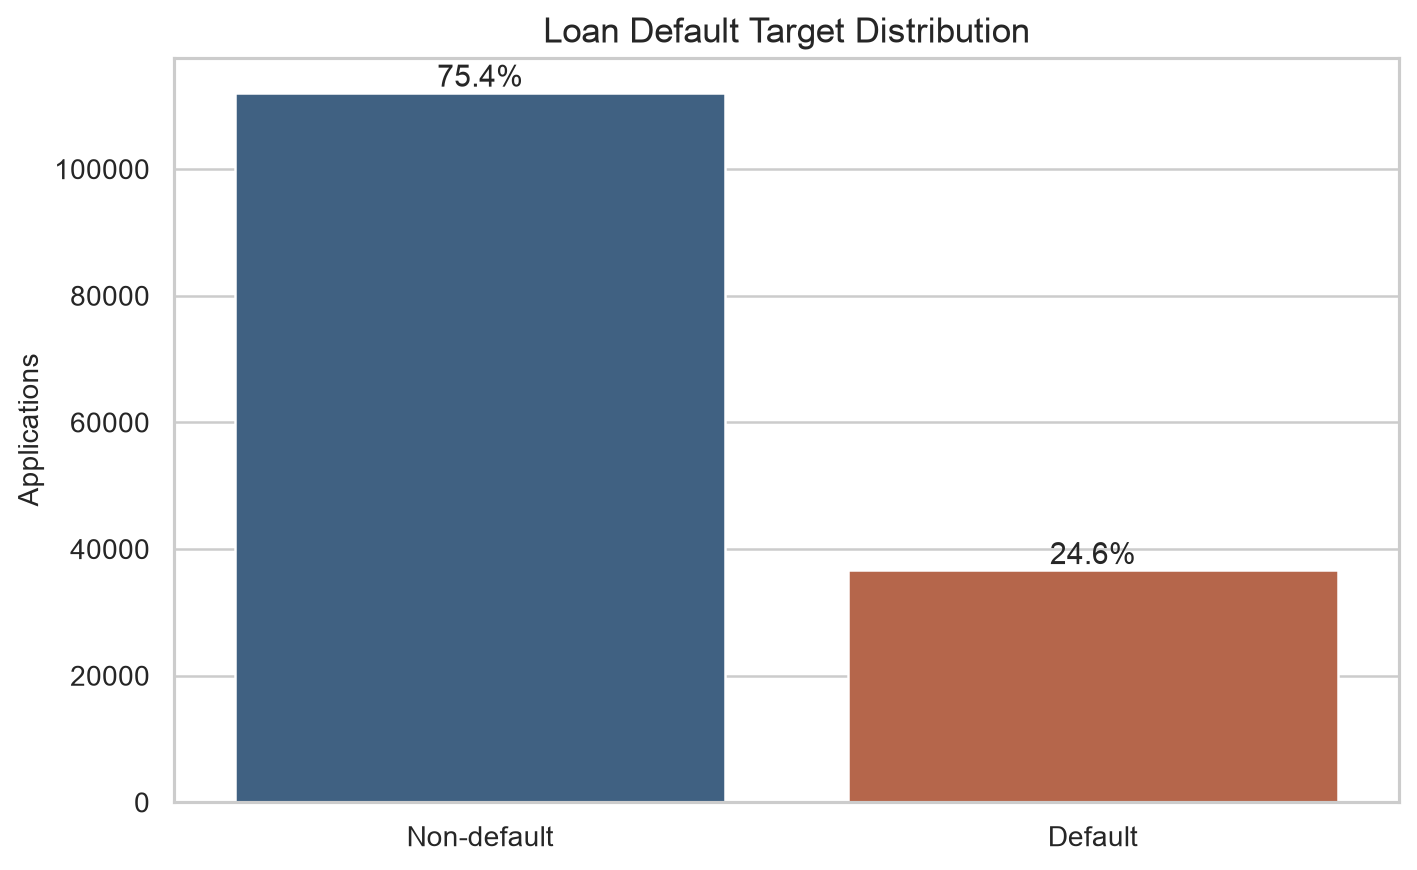

In [7]:
target_balance = df['status'].value_counts().sort_index().rename_axis('status').reset_index(name='count')
target_balance['label'] = target_balance['status'].map({0: 'Non-default', 1: 'Default'})
target_balance['percentage'] = target_balance['count'] / len(df) * 100
save_table(target_balance, EDA_TABLES / 'target_balance.csv')

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=target_balance, x='label', y='count', hue='label', palette=['#35618D', '#C65D3A'], legend=False, ax=ax)
for index, row in target_balance.reset_index(drop=True).iterrows():
    ax.text(index, row['count'], f"{row['percentage']:.1f}%", ha='center', va='bottom')
ax.set_title('Loan Default Target Distribution')
ax.set_xlabel('')
ax.set_ylabel('Applications')
path = save_figure(EDA_FIGURES / 'target_balance.png')
display(target_balance)
display(Image(filename=str(path)))


## 8. Numeric correlation and multicollinearity




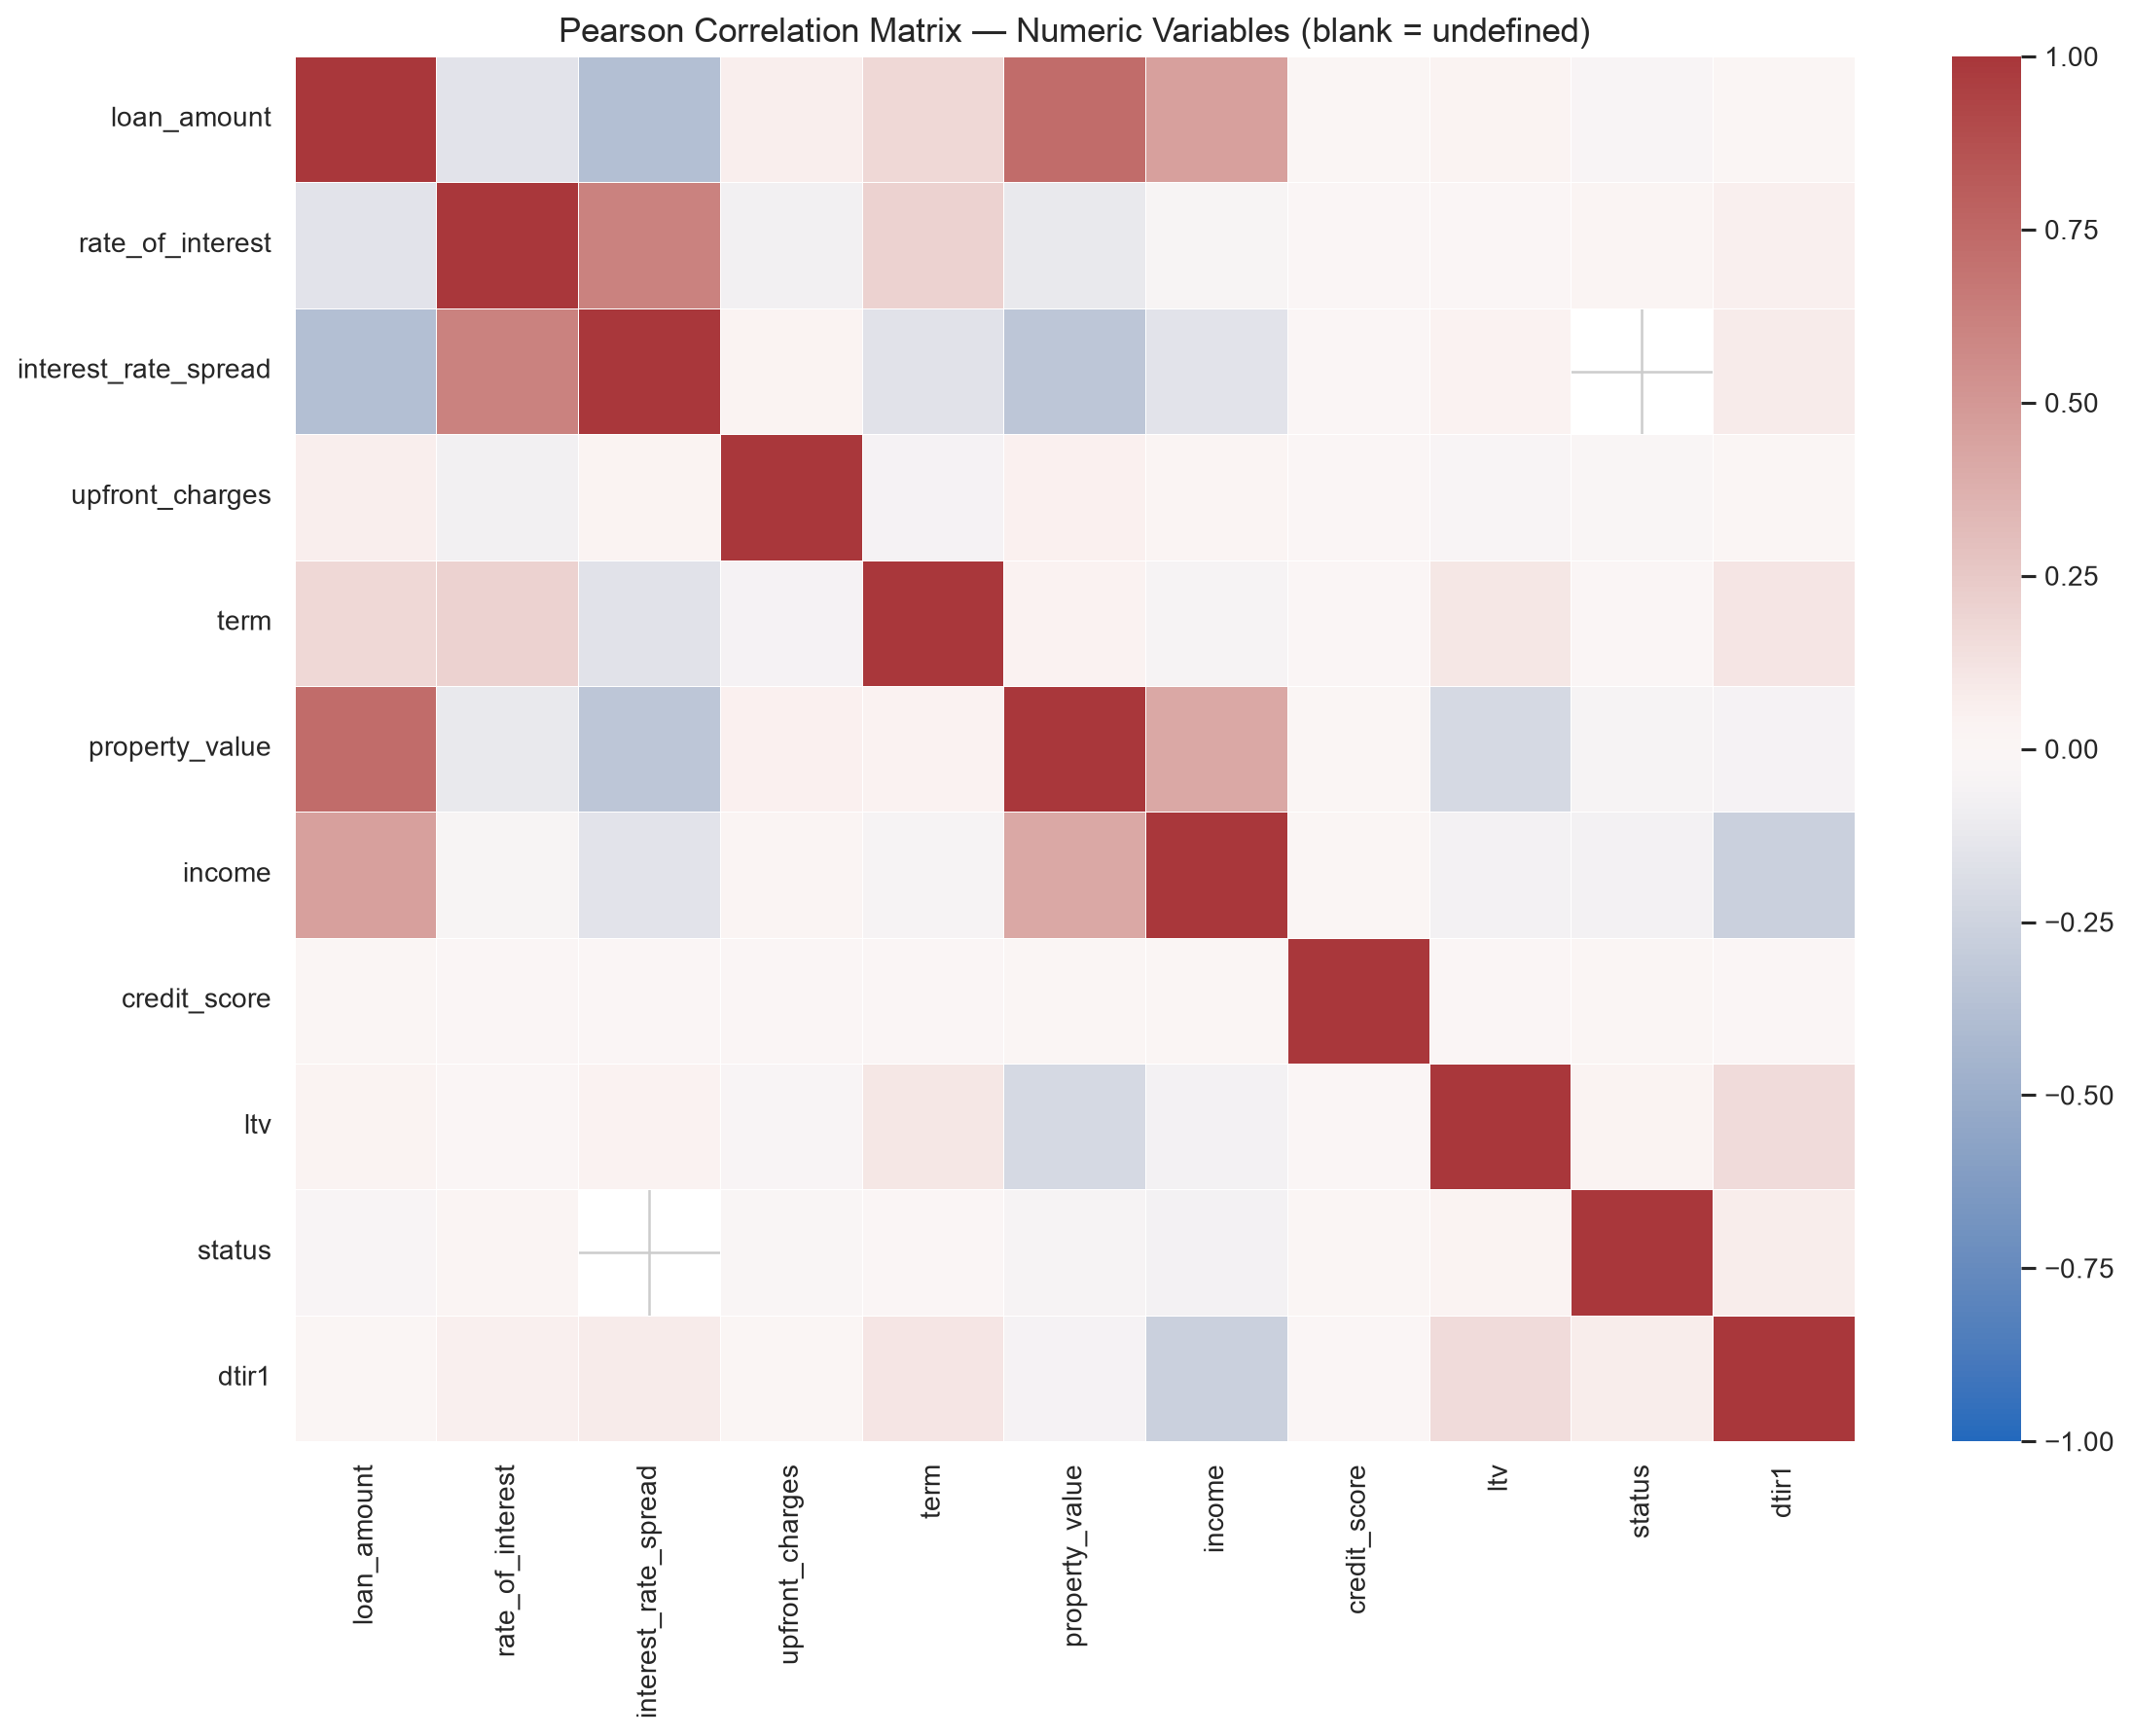

,feature_1,feature_2,correlation,absolute_correlation
4,loan_amount,property_value,0.734249,0.734249
10,rate_of_interest,interest_rate_spread,0.614908,0.614908
5,loan_amount,income,0.456065,0.456065
39,property_value,income,0.414883,0.414883
1,loan_amount,interest_rate_spread,-0.377272,0.377272
21,interest_rate_spread,property_value,-0.334571,0.334571
47,income,dtir1,-0.267807,0.267807
41,property_value,ltv,-0.215102,0.215102
12,rate_of_interest,term,0.209330,0.209330
3,loan_amount,term,0.174474,0.174474


,feature_1,feature_2,correlation_undefined
0,interest_rate_spread,status,True


In [8]:
numeric_for_corr = df.select_dtypes(include=np.number).drop(columns=['id', 'year'], errors='ignore')
corr = numeric_for_corr.corr()
save_table(corr.reset_index(names='feature'), EDA_TABLES / 'numeric_correlation_matrix.csv')

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, mask=corr.isna(), cmap='vlag', center=0, vmin=-1, vmax=1, linewidths=0.35, ax=ax)
ax.set_title('Pearson Correlation Matrix — Numeric Variables (blank = undefined)')
path = save_figure(EDA_FIGURES / 'numeric_correlation_heatmap.png')
display(Image(filename=str(path)))

corr_pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    .stack().rename('correlation').reset_index()
    .rename(columns={'level_0': 'feature_1', 'level_1': 'feature_2'})
)
corr_pairs['absolute_correlation'] = corr_pairs['correlation'].abs()
corr_pairs = corr_pairs.sort_values('absolute_correlation', ascending=False)
upper_triangle = pd.DataFrame(
    np.triu(np.ones(corr.shape), k=1).astype(bool), index=corr.index, columns=corr.columns
)
undefined_pairs = (
    corr.isna().where(upper_triangle).stack()
    .loc[lambda values: values]
    .rename('correlation_undefined')
    .reset_index()
    .rename(columns={'level_0': 'feature_1', 'level_1': 'feature_2'})
)
save_table(corr_pairs, EDA_TABLES / 'numeric_correlation_pairs.csv')
save_table(undefined_pairs, EDA_TABLES / 'undefined_numeric_correlations.csv')
display(corr_pairs.head(20))
display(undefined_pairs)


## 9. Categorical association with the target


In [9]:
categorical_association = categorical_association_with_target(df)
save_table(categorical_association, EDA_TABLES / 'categorical_target_cramers_v.csv')
display(categorical_association)


,feature,cramers_v,chi_square_p_value,categories_including_missing
15,credit_type,0.592181,0.000000,4
10,lump_sum_payment,0.187700,0.000000,2
8,neg_amortization,0.155858,0.000000,3
16,co_applicant_credit_type,0.144223,0.000000,2
18,submission_of_application,0.136711,0.000000,3
3,loan_type,0.093868,0.000000,3
7,business_or_commercial,0.092527,0.000000,2
1,gender,0.083783,0.000000,4
17,age,0.081431,0.000000,8
0,loan_limit,0.053953,0.000000,3


## 10. Outlier investigation


,feature,iqr_lower_bound,iqr_upper_bound,flagged_count,flagged_pct_of_non_missing,observed_min,observed_max
8,term,360.000,360.000,26944,18.128,96.000,3.600000e+02
2,income,-3480.000,15720.000,6546,4.692,0.000,5.785800e+05
6,property_value,-272000.000,1168000.000,5266,3.942,8000.000,1.650800e+07
9,upfront_charges,-5765.025,11159.015,2880,2.642,0.000,6.000000e+04
1,dtir1,10.000,66.000,2013,1.616,5.000,6.100000e+01
5,ltv,21.911,124.748,1882,1.409,0.967,7.831250e+03
4,loan_amount,-163500.000,796500.000,1895,1.275,16500.000,3.576500e+06
7,rate_of_interest,2.500,5.500,856,0.763,0.000,8.000000e+00
3,interest_rate_spread,-0.973,1.824,445,0.397,-3.638,3.357000e+00
0,credit_score,297.500,1101.500,0,0.000,500.000,9.000000e+02


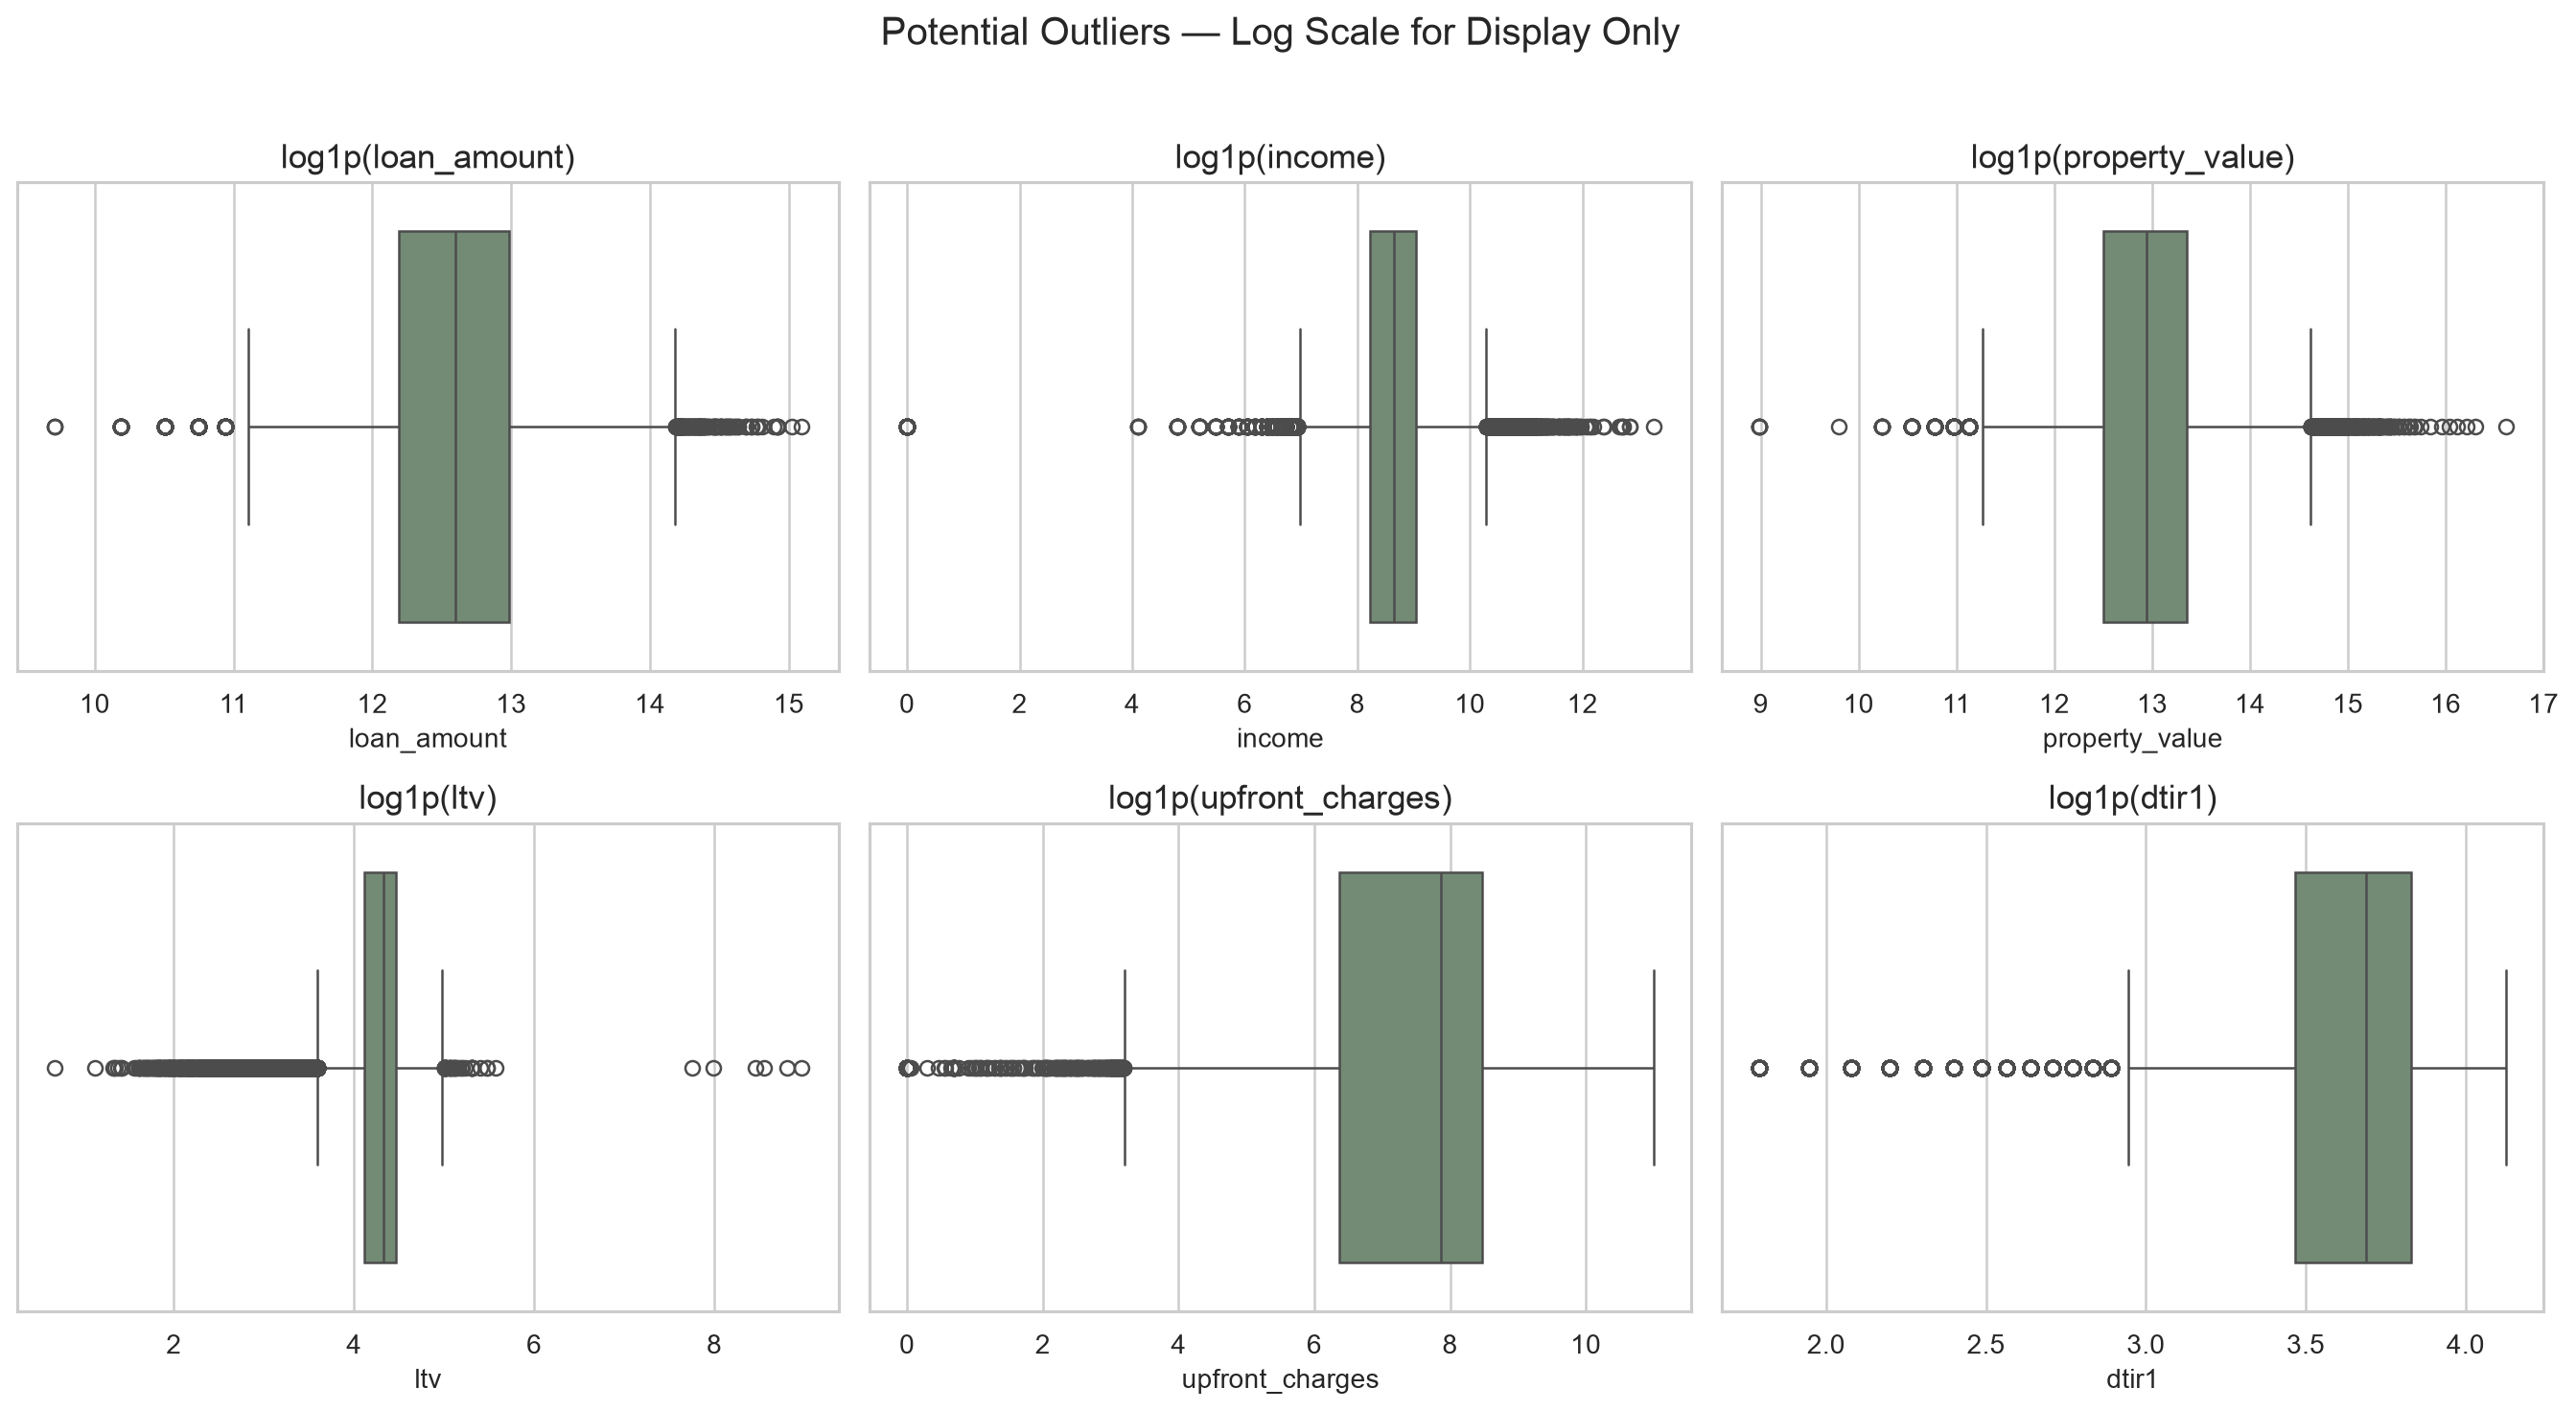

In [10]:
outliers = iqr_outlier_summary(df)
save_table(outliers, EDA_TABLES / 'iqr_outlier_summary.csv')
display(outliers)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for column, ax in zip(['loan_amount', 'income', 'property_value', 'ltv', 'upfront_charges', 'dtir1'], axes.flat):
    transformed = np.log1p(df[column].clip(lower=0))
    sns.boxplot(x=transformed, ax=ax, color='#6F8F72')
    ax.set_title(f'log1p({column})')
fig.suptitle('Potential Outliers — Log Scale for Display Only', y=1.02, fontsize=16)
path = save_figure(EDA_FIGURES / 'numeric_outliers.png')
display(Image(filename=str(path)))
